# 6. Credit Policy

A probability of default by itself is not a decision. This notebook turns the predictions of the model into a **credit approval policy**:

- Which threshold should be used to approve or reject a loan?
- How much money does the policy make compared with approving everyone?
- How can the clients be grouped into risk grades?
- Why does the model consider a specific client risky?

In [15]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

In [16]:
# Load the predictions and the model
train_scores = pd.read_csv("../data/train_scores.csv")
test_scores = pd.read_csv("../data/test_scores.csv")
X_test = pd.read_csv("../data/X_test.csv")

model = joblib.load("../models/xgboost_credit_risk_model.pkl")

test_scores.head()

,LOAN,BAD,PD
0,25100,0,0.007385
1,19600,0,0.051860
2,11000,0,0.015981
3,9600,0,0.128470
4,4000,1,0.635063


## 6.1 Expected loss

In credit risk, the expected loss of a loan is calculated as:

**Expected Loss = PD × LGD × EAD**

- **PD (Probability of Default):** probability that the client will not pay. This is what the model predicts.
- **LGD (Loss Given Default):** share of the loan that the bank loses if the client defaults. As these are home equity loans, the bank can recover part of the money by selling the property, so the LGD is lower than 100%.
- **EAD (Exposure at Default):** amount owed when the client defaults. Here it is approximated with the loan amount (`LOAN`).

On the other side, if a good client is approved, the bank earns a profit from the interest of the loan.

In [17]:
# Business assumptions
LGD = 0.40            # share of the loan lost when a client defaults
PROFIT_MARGIN = 0.10  # net profit earned on a good loan (share of the loan amount)

These assumptions are parameters on purpose. In a real project they would be defined with the risk and finance teams. Changing them changes the optimal threshold, but the method stays the same.

## 6.2 Break-even probability

A loan should be approved when the expected profit is higher than the expected loss:

`(1 − PD) × PROFIT_MARGIN × LOAN  >  PD × LGD × LOAN`

Solving for PD:

`PD  <  PROFIT_MARGIN / (PROFIT_MARGIN + LGD)`

In [18]:
# Theoretical break-even threshold
break_even = PROFIT_MARGIN / (PROFIT_MARGIN + LGD)
print(f"Break-even PD: {break_even:.0%}")

Break-even PD: 20%


With these assumptions, any client with a probability of default below **20%** is profitable on average. This is very different from the default threshold of 50% used by `model.predict()`, which does not consider that losing money on a bad loan costs four times more than the profit of a good one.

## 6.3 Choosing the threshold

The threshold is chosen using the **out-of-fold predictions of the training set**, so the test set is still not used. For each possible threshold, the loans with a PD below it are approved and the total profit is calculated.

In [19]:
# Function to simulate a credit policy for a given threshold
def simulate_policy(scores, threshold):
    approved = scores[scores['PD'] < threshold]

    profit_good = (approved['LOAN'] * PROFIT_MARGIN * (1 - approved['BAD'])).sum()
    loss_bad = (approved['LOAN'] * LGD * approved['BAD']).sum()

    return {
        'threshold': threshold,
        'approval_rate': len(approved) / len(scores),
        'default_rate_approved': approved['BAD'].mean(),
        'defaults_approved': int(approved['BAD'].sum()),
        'profit': profit_good - loss_bad
    }

In [20]:
# Simulate the profit for every threshold between 1% and 100%
thresholds = np.arange(0.01, 1.01, 0.01)

policy_curve = pd.DataFrame([simulate_policy(train_scores, t) for t in thresholds])

best = policy_curve.loc[policy_curve['profit'].idxmax()]
best_threshold = round(best['threshold'], 2)

print(f"Best threshold: {best_threshold:.0%}")

Best threshold: 12%


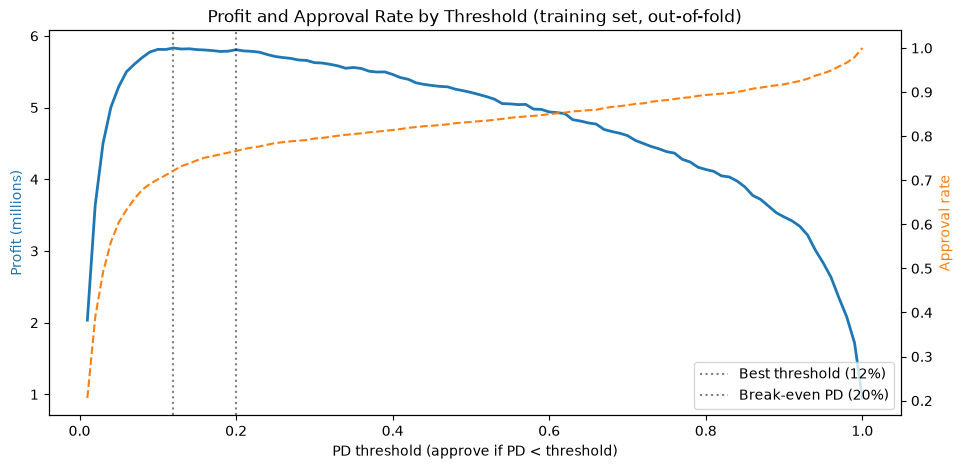

In [21]:
# Plot the profit and the approval rate by threshold
fig, ax1 = plt.subplots(figsize=(11, 5))

ax1.plot(policy_curve['threshold'], policy_curve['profit'] / 1e6, color='tab:blue', linewidth=2)
ax1.set_xlabel('PD threshold (approve if PD < threshold)')
ax1.set_ylabel('Profit (millions)', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(policy_curve['threshold'], policy_curve['approval_rate'], color='tab:orange', linestyle='--')
ax2.set_ylabel('Approval rate', color='tab:orange')

ax1.axvline(best_threshold, color='grey', linestyle=':', label=f'Best threshold ({best_threshold:.0%})')
ax1.axvline(break_even, color='black', linestyle=':', alpha=0.5, label=f'Break-even PD ({break_even:.0%})')
ax1.legend(loc='lower right')

plt.title('Profit and Approval Rate by Threshold (training set, out-of-fold)')
plt.show()

The profit curve is quite flat between ~10% and ~20%, and the best threshold is close to the theoretical break-even point. This is a good sign that the predicted probabilities are well calibrated.

Above the threshold, the profit falls quickly: each additional approved client has a high probability of default and the losses are higher than the interest earned.

## 6.4 Policy evaluation on the test set

The chosen threshold is now applied to the test set and compared with two alternatives:

- **Approve everyone:** the situation without a model.
- **Default threshold (50%):** what `model.predict()` would do.

In [22]:
# Compare the policies on the test set
policies = pd.DataFrame([
    simulate_policy(test_scores, 1.01),
    simulate_policy(test_scores, 0.50),
    simulate_policy(test_scores, best_threshold)
], index=['Approve everyone', 'Default threshold (50%)', f'Optimal threshold ({best_threshold:.0%})'])

policies.style.format({
    'threshold': '{:.0%}',
    'approval_rate': '{:.1%}',
    'default_rate_approved': '{:.1%}',
    'profit': '{:,.0f}'
})

,threshold,approval_rate,default_rate_approved,defaults_approved,profit
Approve everyone,101%,100.0%,20.0%,238,"81,290"
Default threshold (50%),50%,83.7%,7.5%,75,"1,198,550"
Optimal threshold (12%),12%,71.8%,2.8%,24,"1,447,570"


Without a model, approving all the clients is barely profitable, because the losses from the ~20% of defaulters almost cancel the profit from the good clients.

Using the model with the optimal threshold, the bank approves around three out of four applications and the default rate of the approved portfolio drops to a few percent, which multiplies the profit compared with approving everyone. It also makes more money than the default 50% threshold, which approves clients whose expected loss is higher than their expected profit.

## 6.5 Risk grades

Banks usually group clients into **risk grades** instead of using the raw probability. Each grade has a PD range and a recommended action. If the model is good, the observed default rate should increase from one grade to the next.

In [23]:
# Define the risk grades by PD range
grade_bins = [0, 0.02, 0.05, 0.10, 0.20, 0.50, 1.0]
grade_labels = ['A', 'B', 'C', 'D', 'E', 'F']

test_scores['grade'] = pd.cut(test_scores['PD'], bins=grade_bins, labels=grade_labels, include_lowest=True)

risk_grades = test_scores.groupby('grade', observed=True).agg(
    clients=('PD', 'size'),
    avg_predicted_PD=('PD', 'mean'),
    observed_default_rate=('BAD', 'mean'),
    avg_loan=('LOAN', 'mean')
)

risk_grades['share_of_clients'] = risk_grades['clients'] / risk_grades['clients'].sum()
risk_grades['action'] = ['Approve', 'Approve', 'Approve', 'Approve with review', 'Reject', 'Reject']

risk_grades.style.format({
    'avg_predicted_PD': '{:.1%}',
    'observed_default_rate': '{:.1%}',
    'avg_loan': '{:,.0f}',
    'share_of_clients': '{:.1%}'
})

,clients,avg_predicted_PD,observed_default_rate,avg_loan,share_of_clients,action
grade,,,,,,
A,432,1.0%,0.9%,"20,534",36.2%,Approve
B,289,3.3%,2.1%,"18,659",24.2%,Approve
C,115,6.9%,11.3%,"17,543",9.6%,Approve
D,76,13.8%,21.1%,"17,607",6.4%,Approve with review
E,86,32.9%,41.9%,"17,010",7.2%,Reject
F,194,82.6%,84.0%,"17,845",16.3%,Reject


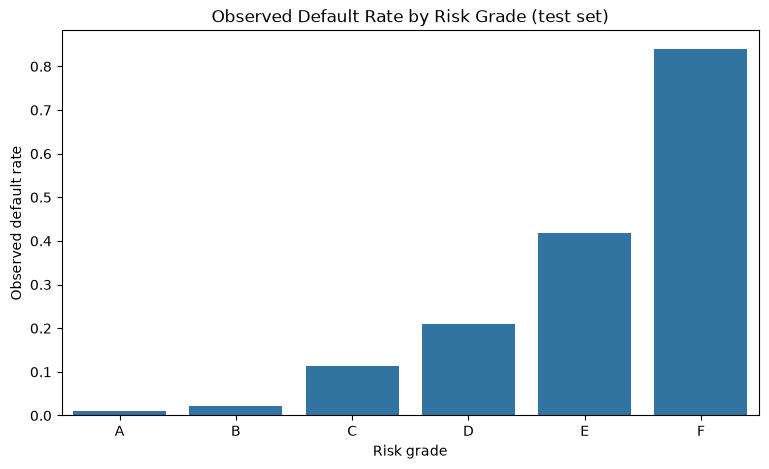

In [24]:
# Plot the observed default rate by risk grade
plt.figure(figsize=(9, 5))
sns.barplot(x=risk_grades.index, y=risk_grades['observed_default_rate'], color='tab:blue')

plt.title('Observed Default Rate by Risk Grade (test set)')
plt.xlabel('Risk grade')
plt.ylabel('Observed default rate')
plt.show()

The observed default rate increases with each grade, so the model ranks the clients correctly. Around 60% of the clients fall into grades A and B, with an observed default rate of 2% or less, while grade F concentrates the clients that are almost certain to default.

In grades C, D and E the observed default rate is higher than the predicted PD. This is the underestimation seen in the calibration curve, and it is the reason why grade D is approved only after a manual review.

## 6.6 Expected loss of the approved portfolio

With the optimal policy, the expected loss of the approved loans can be estimated with the formula from section 6.1 and compared with the real loss in the test set.

In [25]:
# Compare the expected loss with the real loss of the approved portfolio
approved = test_scores[test_scores['PD'] < best_threshold].copy()

approved['expected_loss'] = approved['PD'] * LGD * approved['LOAN']
approved['real_loss'] = approved['BAD'] * LGD * approved['LOAN']

print(f"Approved loans:      {len(approved):,}")
print(f"Total amount lent:   {approved['LOAN'].sum():,.0f}")
print(f"Expected loss:       {approved['expected_loss'].sum():,.0f}")
print(f"Real loss:           {approved['real_loss'].sum():,.0f}")

Approved loans:      856
Total amount lent:   16,606,200
Expected loss:       175,494
Real loss:           170,440


The real loss is around 25% higher than the expected loss, which is consistent with the underestimation of risk observed in the middle grades. In a bank, the expected loss is used to set aside provisions (money reserved to cover future losses) and to price the loans, so this gap would be a reason to recalibrate the model before using it.

## 6.7 Model interpretation with SHAP

Credit decisions must be explainable: regulators require banks to tell clients the main reasons why a loan was rejected. SHAP shows how much each variable increases or decreases the predicted risk of each client.

In [26]:
# Transform the test set with the preprocessing step of the pipeline
preprocessor = model.named_steps['preprocessor']
xgb_model = model.named_steps['model']

X_test_transformed = preprocessor.transform(X_test)
feature_names = [name.split('__')[1] for name in preprocessor.get_feature_names_out()]

X_test_transformed = pd.DataFrame(X_test_transformed, columns=feature_names)

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer(X_test_transformed)

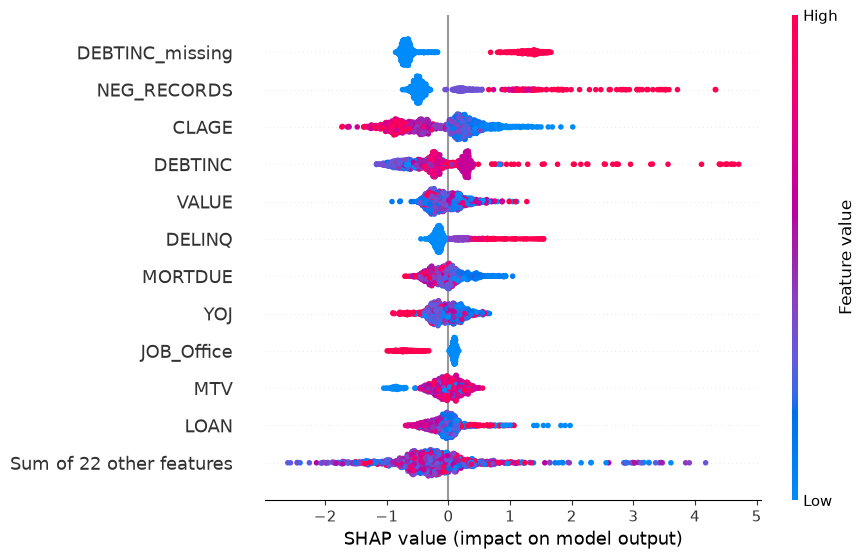

In [27]:
# Global importance: which variables have the biggest impact on the predictions
shap.plots.beeswarm(shap_values, max_display=12)

Each point is a client. The position on the horizontal axis shows how much that variable increases (right) or decreases (left) the predicted risk, and the color shows if the value of the variable is high (red) or low (blue).

- `DEBTINC_missing` is the most important variable: when the debt-to-income ratio is missing, the risk increases strongly, as seen in the EDA.
- `NEG_RECORDS` and `DELINQ` increase the risk when the client has negative records in the credit history. The feature created in notebook 4 is the second most important variable.
- A long credit history (`CLAGE`) reduces the risk.
- Very high values of `DEBTINC` increase the risk strongly.
- Small loans (`LOAN`) are associated with a higher risk, which matches the high default rate of the lowest LTV group seen in notebook 4.

Predicted PD: 29.9% | Real outcome (BAD): 1


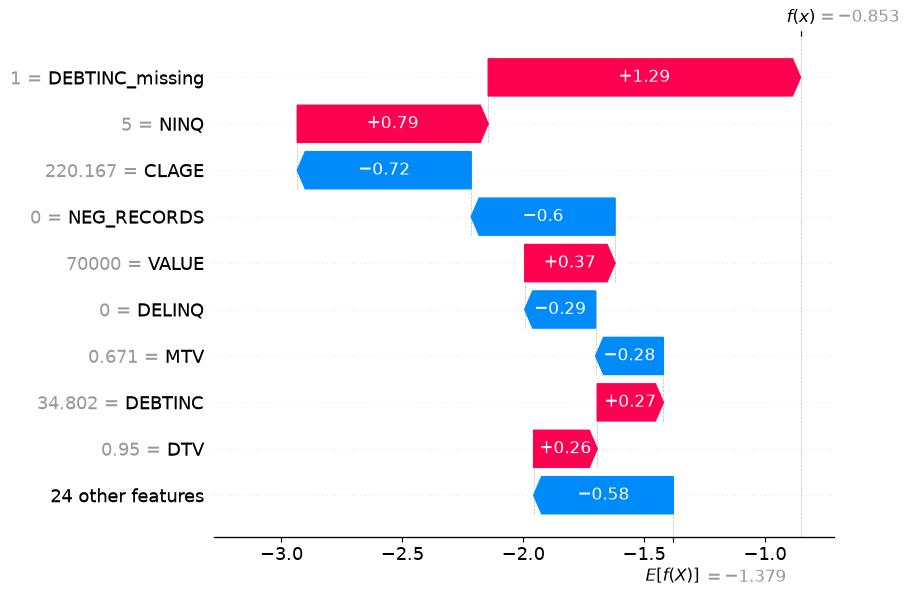

In [28]:
# Local explanation: a rejected client close to the decision threshold (PD around 30%)
client = (test_scores['PD'] - 0.30).abs().values.argmin()

print(f"Predicted PD: {test_scores['PD'].iloc[client]:.1%} | Real outcome (BAD): {test_scores['BAD'].iloc[client]}")

shap.plots.waterfall(shap_values[client], max_display=10)

The waterfall plot starts from the average risk of the portfolio (bottom) and shows how each variable moves the prediction for this client up or down. The values are in log-odds, the scale used internally by XGBoost before converting the result into a probability. This client has a PD of 30%, above the threshold, so the loan would be rejected. The main reasons are the missing debt-to-income ratio and two delinquent credit lines, partially compensated by a long credit history (`CLAGE` of 289 months). The value shown for `DEBTINC` is the median used to fill the missing value, not real information about the client.

This is the type of explanation that could be used as **reason codes** in a rejection letter. It is also a reminder of the cost of any threshold: this client actually repaid the loan. With a PD of 30%, 7 out of 10 similar clients would repay, but on average the losses from the other 3 are higher than the profit.

## Credit Policy Conclusions

- A probability of default needs a business rule to become a decision. With an LGD of 40% and a profit margin of 10%, the break-even PD is 20%.
- The optimal threshold, chosen on the training data, is close to that break-even point and much lower than the default 50% threshold.
- On the test set, the optimal policy approves around three out of four clients, reduces the default rate of the approved portfolio to a few percent, and multiplies the profit compared with approving everyone.
- The risk grades show a clear increase in the observed default rate, which makes the model easy to use in practice.
- SHAP explains both the global behaviour of the model and the reasons for individual decisions.

### Limitations

- The HMEQ dataset is small and old, and has no time dimension. A real model would be validated on more recent applications (out-of-time validation).
- The importance of `DEBTINC_missing` should be checked with the business: it is necessary to confirm why the value is missing and that this information is available when the application is evaluated.
- Variables such as `JOB` should be reviewed for fairness before being used in real lending decisions.
- The LGD and profit margin are assumptions. The policy should be recalculated with real values.